# Embeddings Example 1

> Setentence Transformers

## setup

In [8]:
# Install first (if you don’t have it yet):
# pip install sentence-transformers

from sentence_transformers import SentenceTransformer
from scipy.spatial.distance import cosine
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Loading an embeddings model
model = SentenceTransformer("all-MiniLM-L6-v2")


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5791.06it/s]


## Sentences

In [2]:
# Texts to transform into embeddings
sentences = [
    "The cat is sleeping on the couch.",
    "A dog is lying on the couch.",
    "The car is red.",
    "I love programming with Python.",
    "The sofa is comfortable.",
]

## Generating embeddings

In [3]:
# Generating embeddings (vectors)
embeddings = model.encode(sentences)
print(len(embeddings))

if len(embeddings) == len(sentences):
    print("Embeddings gerados com sucesso!")
    print(embeddings[0].shape)

5
Embeddings gerados com sucesso!
(384,)


## Showing dimensions and first values

In [4]:
# Showing dimensions and first values
for i, sentence in enumerate(sentences):
    print(f"\nText: {sentence}")
    print(f"Embedding dimensions: {len(embeddings[i])}")
    print(f"First 5 values: {embeddings[i][:5]}")


Text: The cat is sleeping on the couch.
Embedding dimensions: 384
First 5 values: [ 0.12316934 -0.04497078 -0.00639322  0.05534335  0.01913957]

Text: A dog is lying on the couch.
Embedding dimensions: 384
First 5 values: [ 0.01974738 -0.03369004  0.01261227  0.06838799  0.00938515]

Text: The car is red.
Embedding dimensions: 384
First 5 values: [-0.02466983  0.03748173 -0.05057453  0.03706826 -0.01616983]

Text: I love programming with Python.
Embedding dimensions: 384
First 5 values: [-0.07513767 -0.00679392 -0.01778841  0.02785116 -0.00793511]

Text: The sofa is comfortable.
Embedding dimensions: 384
First 5 values: [ 0.11710946 -0.08672937 -0.0541902   0.03538611  0.02275899]


## Similarity

In [5]:
# Show cosine similarity between each pair
print("\nCosine similarities:")
for i in range(len(sentences)):
    for j in range(i + 1, len(sentences)):
        sim = 1 - cosine(embeddings[i], embeddings[j])
        print(
            f"Similarity between:\n - '{sentences[i]}'\n - '{sentences[j]}'\n = {sim:.4f}\n"
        )


Cosine similarities:
Similarity between:
 - 'The cat is sleeping on the couch.'
 - 'A dog is lying on the couch.'
 = 0.5089

Similarity between:
 - 'The cat is sleeping on the couch.'
 - 'The car is red.'
 = -0.0390

Similarity between:
 - 'The cat is sleeping on the couch.'
 - 'I love programming with Python.'
 = 0.0513

Similarity between:
 - 'The cat is sleeping on the couch.'
 - 'The sofa is comfortable.'
 = 0.3885

Similarity between:
 - 'A dog is lying on the couch.'
 - 'The car is red.'
 = 0.0551

Similarity between:
 - 'A dog is lying on the couch.'
 - 'I love programming with Python.'
 = 0.0603

Similarity between:
 - 'A dog is lying on the couch.'
 - 'The sofa is comfortable.'
 = 0.4441

Similarity between:
 - 'The car is red.'
 - 'I love programming with Python.'
 = -0.0078

Similarity between:
 - 'The car is red.'
 - 'The sofa is comfortable.'
 = -0.0203

Similarity between:
 - 'I love programming with Python.'
 - 'The sofa is comfortable.'
 = 0.0824



## Plot

👉 This will:

* Convert each sentence into a 384-dimensional embedding.

* Reduce to 2D with PCA for visualization.

* Plot the sentences, showing that semantically similar ones (e.g., cat/dog/sofa) cluster together, while unrelated ones (like car or Python programming) are farther away.

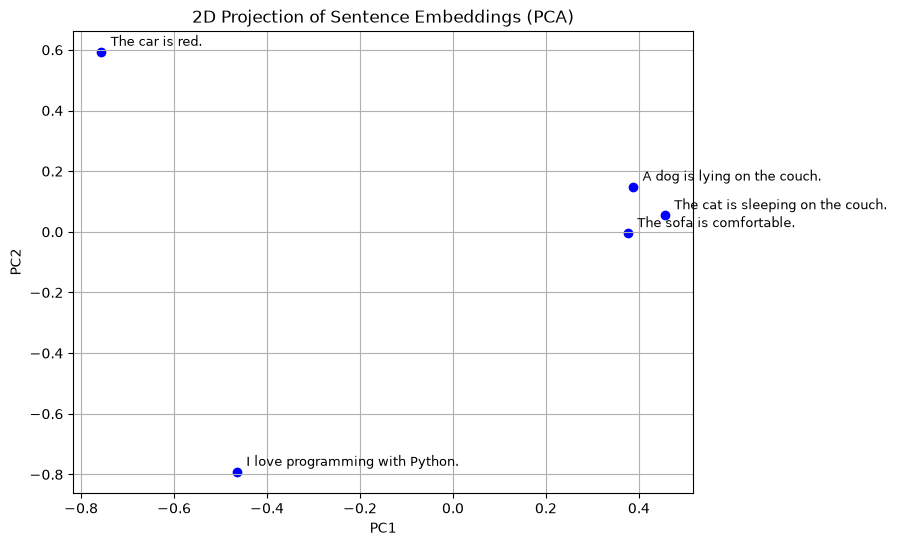

In [6]:
# Reduce embeddings to 2D with PCA
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(embeddings)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], color="blue")

for i, sentence in enumerate(sentences):
    plt.annotate(
        sentence, (embeddings_2d[i, 0] + 0.02, embeddings_2d[i, 1] + 0.02), fontsize=9
    )

plt.title("2D Projection of Sentence Embeddings (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.show()

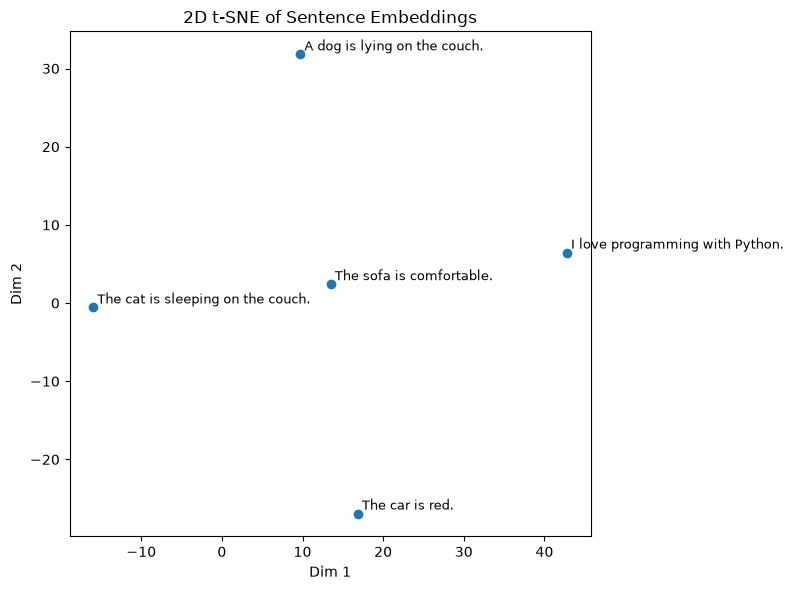

In [7]:
from sklearn.manifold import TSNE

# 4) Safe PCA: number of components = min(n_samples-1, embedding_dim, 50)
n_components = min(len(sentences) - 1, embeddings.shape[1], 50)
emb_reduced = PCA(n_components=n_components, random_state=42).fit_transform(embeddings)

# 5) t-SNE to 2D
tsne = TSNE(
    n_components=2,
    perplexity=4,
    learning_rate="auto",
    init="pca",
    random_state=42,
)
emb_2d = tsne.fit_transform(emb_reduced)

# 6) Plot
plt.figure(figsize=(8, 6))
plt.scatter(emb_2d[:, 0], emb_2d[:, 1])

for i, text in enumerate(sentences):
    plt.annotate(text, (emb_2d[i, 0] + 0.5, emb_2d[i, 1] + 0.5), fontsize=9)

plt.title("2D t-SNE of Sentence Embeddings")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.tight_layout()
plt.show()
